In [1]:
amostra = '23_08'

In [2]:
import tensorflow as tf
import keras
print(tf.__version__)
print(keras.__version__)

2024-10-23 10:22:37.525968: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-10-23 10:22:37.533360: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-23 10:22:37.542835: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-23 10:22:37.542851: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-23 10:22:37.550568: I tensorflow/core/platform/cpu_feature_gua

2.16.2
3.3.3


In [3]:
#Make sure the GPU is available. 
import tensorflow as tf
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

Found GPU at: /device:GPU:0


2024-10-23 10:22:38.397654: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:38.411620: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:38.411655: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:38.518490: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:38.518533: I external/local_xla/xla/stream_executor

In [4]:
physical_devices = tf.config.list_physical_devices('GPU')
tf.config.experimental.set_memory_growth(physical_devices[0], True)

2024-10-23 10:22:38.527248: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:38.527306: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:38.527323: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [5]:
import segmentation_models_3D as sm


Segmentation Models: using `keras` framework.


In [6]:
from skimage import io
from patchify import patchify, unpatchify
import numpy as np
from matplotlib import pyplot as plt
from keras import backend as K
from keras.utils import to_categorical
from sklearn.model_selection import train_test_split, LeaveOneOut
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import os
import gc

In [7]:
import albumentations as A

# Data Augmentation
augmentation = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Transpose(),
    A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.50, rotate_limit=45, p=.75),
    A.ElasticTransform(alpha=120, sigma=120 * 0.05, alpha_affine=None, p=0.5),
    A.GridDistortion(p=0.5),
    A.CoarseDropout(max_holes=8, max_height=16, max_width=16, p=0.5),
     A.OpticalDistortion(),
])

INFO:albumentations.check_version:A new version of Albumentations is available: 1.4.18 (you have 1.4.12). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.


In [8]:
def readImages(folder, n_patch = 64, step = 64):
    file_combined = os.path.join(folder,'output_combined_matriz_fibras.tif')
    file_fibras = os.path.join(folder,'output_fibras.tif')

    image = io.imread(file_combined)
    mask = io.imread(file_fibras)
    image_patches = patchify(image, (n_patch, n_patch, n_patch), step=step)
    mask_patches = patchify(mask, (n_patch, n_patch, n_patch), step=step)
    image_patches = np.reshape(image_patches, (-1, image_patches.shape[3], image_patches.shape[4], image_patches.shape[5]))
    mask_patches = np.reshape(mask_patches, (-1, mask_patches.shape[3], mask_patches.shape[4], mask_patches.shape[5]))
    return image_patches, mask_patches

In [9]:
def createTrainLOO(folders, test_folder, augmentData=True):
    train_images = []
    train_masks = []
    
    # Excluímos a pasta de teste e usamos o restante para treinamento
    selected_folders = [folder for folder in folders if folder != test_folder]
    
    for folder in selected_folders:
        image_patches, mask_patches = readImages(folder)
        
        if augmentData:
            augment_test_data(image_patches, mask_patches, train_images, train_masks)
        else:
            train_images.extend(image_patches)
            train_masks.extend(mask_patches)
    
    train_images = np.array(train_images).astype(np.uint8)
    train_masks = np.array(train_masks).astype(np.uint8)
    
    return train_images, train_masks

In [10]:
def apply_augmentation(image, mask):
    augmented = augmentation(image=image, mask=mask)
    return augmented['image'], augmented['mask']

def augment_test_data(image_patches, mask_patches, train_images, train_masks):
    for i in range(image_patches.shape[0]):
        img_patch = image_patches[i, :, :, :]
        mask_patch = mask_patches[i, :, :, :]
        train_images.append(img_patch)
        train_masks.append(mask_patch)
        img_aug, mask_aug = apply_augmentation(img_patch, mask_patch)
        train_images.append(img_aug)
        train_masks.append(mask_aug)

def preprocess(images, masks):
    images = (images/255).astype(np.uint8)
    masks = (masks/255).astype(np.uint8)
    images = np.stack((images,)*3, axis=-1)
    masks = np.expand_dims(masks, axis=4)
    
    return images, masks

In [11]:
path_steel_stl= '../../steel/stl'
paths = [os.path.join(path_steel_stl, folder) for folder in os.listdir(path_steel_stl)]
folders = [folder for folder in paths if os.path.isdir(folder)]

In [12]:
n_classes=2
augmentData = False
preProcessInp = True
test_folder = amostra
path_steel_stl= '../../steel/stl/'
path_test_folder = path_steel_stl + test_folder
train_images, train_masks = createTrainLOO(folders, path_test_folder, augmentData)
print(train_images.shape)
print(train_masks.shape)

(640, 64, 64, 64)
(640, 64, 64, 64)


In [13]:
train_images, train_masks = preprocess(train_images, train_masks)
print(train_images.shape)
print(train_masks.shape)

(640, 64, 64, 64, 3)
(640, 64, 64, 64, 1)


In [14]:
train_mask_cat = to_categorical(train_masks, num_classes=n_classes)
X_train, X_test, y_train, y_test = train_test_split(train_images, train_mask_cat, test_size = 0.10, random_state = 0)

In [15]:
train_mask_cat.shape

(640, 64, 64, 64, 2)

Backbones: ['resnet18', 'resnet34', 'resnet50', 'resnet101', 'resnet152', 'seresnet18', 'seresnet34', 'seresnet50', 'seresnet101', 'seresnet152', 'seresnext50', 'seresnext101', 'senet154', 'resnext50', 'resnext101', 'vgg16', 'vgg19', 'densenet121', 'densenet169', 'densenet201', 'inceptionresnetv2', 'inceptionv3', 'mobilenet', 'mobilenetv2', 'efficientnetb0', 'efficientnetb1', 'efficientnetb2', 'efficientnetb3', 'efficientnetb4', 'efficientnetb5', 'efficientnetb6', 'efficientnetb7']

In [16]:
#Define parameters for our model.

policy = tf.keras.mixed_precision.Policy('mixed_float16')
tf.keras.mixed_precision.set_global_policy(policy)

encoder_weights = 'imagenet'
BACKBONE = 'resnet18'  #Try vgg16, efficientnetb7, inceptionv3, resnet50
activation = 'softmax'
patch_size = 64
channels=3
n_epochs = 100
batch_size = 1


# Segmentation models losses can be combined together by '+' and scaled by integer or float factor
# set class weights for dice_loss (car: 1.; pedestrian: 2.; background: 0.5;)
dice_loss = sm.losses.DiceLoss(class_weights=np.array([0.5, 0.5])) 
focal_loss = sm.losses.CategoricalFocalLoss()
total_loss = dice_loss + (1 * focal_loss)

# actulally total_loss can be imported directly from library, above example just show you how to manipulate with losses
# total_loss = sm.losses.binary_focal_dice_loss # or sm.losses.categorical_focal_dice_loss 

metrics = [sm.metrics.IOUScore(threshold=0.5), sm.metrics.FScore(threshold=0.5)]

In [17]:
preprocess_input = sm.get_preprocessing(BACKBONE)

In [18]:
#Preprocess input data - otherwise you end up with garbage resutls 
# and potentially model that does not converge.
if preProcessInp:
    X_train_prep = preprocess_input(X_train)
    X_test_prep = preprocess_input(X_test)
else:
    X_train_prep = X_train
    X_test_prep = X_test

In [19]:
X_test_prep.shape

(64, 64, 64, 64, 3)

In [20]:
from tensorflow.keras.optimizers.schedules import ExponentialDecay


# Define configuration parameters
initial_learning_rate = 0.0001
min_lr = 0.000001
max_lr = 0.001
rampup_epochs = 10
sustain_epochs = 0
exp_decay = 0.8

# Define the scheduling function
def schedule(epoch):
  def lr(epoch, initial_learning_rate, min_lr, max_lr, rampup_epochs, sustain_epochs, exp_decay):
    if epoch < rampup_epochs:
      lr = (max_lr - initial_learning_rate)/rampup_epochs * epoch + initial_learning_rate
    elif epoch < rampup_epochs + sustain_epochs:
      lr = max_lr
    else:
      lr = (max_lr - min_lr) * exp_decay**(epoch-rampup_epochs-sustain_epochs) + min_lr
    return lr
  return lr(epoch, initial_learning_rate, min_lr, max_lr, rampup_epochs, sustain_epochs, exp_decay)
optimizer = keras.optimizers.Adam(learning_rate=initial_learning_rate)

lr_callback = tf.keras.callbacks.LearningRateScheduler(lambda epoch: schedule(epoch), verbose=True)

2024-10-23 10:22:41.982460: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:41.982513: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:41.982532: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:41.982645: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2024-10-23 10:22:41.982652: I tensorflow/core/common_runtime/gpu/gpu

In [21]:
#Define the model. Here we use Unet but we can also use other model architectures from the library.
model = sm.Unet(BACKBONE, classes=n_classes, 
                input_shape=(patch_size, patch_size, patch_size, channels), 
                encoder_weights=encoder_weights,
                activation=activation)

model.compile(optimizer = optimizer, loss=total_loss, metrics=metrics)
print(model.summary())

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ data (InputLayer)   │ (None, 64, 64,    │          0 │ -                 │
│                     │ 64, 3)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_data             │ (None, 64, 64,    │          9 │ data[0][0]        │
│ (BatchNormalizatio… │ 64, 3)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding3d      │ (None, 70, 70,    │          0 │ bn_data[0][0]     │
│ (ZeroPadding3D)     │ 70, 3)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv0 (Conv3D)      │ (None, 32, 32,    │     65,856 │ zero_padding3d[0… │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn0                 │ (None, 32, 32,    │        256 │ conv0[0][0]       │
│ (BatchNormalizatio… │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ relu0 (Activation)  │ (None, 32, 32,    │          0 │ bn0[0][0]         │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding3d_1    │ (None, 34, 34,    │          0 │ relu0[0][0]       │
│ (ZeroPadding3D)     │ 34, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pooling0            │ (None, 16, 16,    │          0 │ zero_padding3d_1… │
│ (MaxPooling3D)      │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_bn1    │ (None, 16, 16,    │        256 │ pooling0[0][0]    │
│ (BatchNormalizatio… │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_relu1  │ (None, 16, 16,    │          0 │ stage1_unit1_bn1… │
│ (Activation)        │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding3d_2    │ (None, 18, 18,    │          0 │ stage1_unit1_rel… │
│ (ZeroPadding3D)     │ 18, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_conv1  │ (None, 16, 16,    │    110,592 │ zero_padding3d_2… │
│ (Conv3D)            │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_bn2    │ (None, 16, 16,    │        256 │ stage1_unit1_con… │
│ (BatchNormalizatio… │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_relu2  │ (None, 16, 16,    │          0 │ stage1_unit1_bn2… │
│ (Activation)        │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding3d_3    │ (None, 18, 18,    │          0 │ stage1_unit1_rel… │
│ (ZeroPadding3D)     │ 18, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_conv2  │ (None, 16, 16,    │    110,592 │ zero_padding3d_3… │
│ (Conv3D)            │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stage1_unit1_sc     │ (None, 16, 16,    │      4,096 │ stage1_unit1_rel

 Total params: 42,667,819 (162.76 MB)

 Trainable params: 42,657,893 (162.73 MB)

 Non-trainable params: 9,926 (38.77 KB)

None


In [22]:
from datetime import datetime

folder_trained_models = 'trained_models/'
name_model = f'{amostra}_{BACKBONE}_prepr{preProcessInp}_aug_{augmentData}_{n_epochs}epochs_{datetime.now():%Y-%m-%d %H-%m-%d}'
namefile = folder_trained_models + name_model + '.keras'


checkpoint = ModelCheckpoint(namefile, monitor='val_iou_score', save_best_only=True, mode='max')
early_stopping = EarlyStopping(monitor='val_iou_score', patience=10, mode='max', restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_iou_score', factor=0.2, patience=10, min_lr=min_lr)

callbacks = [checkpoint, reduce_lr, lr_callback, early_stopping]

In [23]:
#Fit the model
import time
start_time = time.time()

history=model.fit(X_train_prep, 
          y_train,
          batch_size=batch_size, 
          epochs=n_epochs,
          verbose=1,
          validation_data=(X_test_prep, y_test),
          callbacks=callbacks)


Epoch 1: LearningRateScheduler setting learning rate to 0.0001.
Epoch 1/100


I0000 00:00:1729689769.191785   77144 service.cc:145] XLA service 0x7fd664053320 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1729689769.191820   77144 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Ti, Compute Capability 8.9
2024-10-23 10:22:49.313214: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-10-23 10:22:50.137843: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907
I0000 00:00:1729689779.382173   77144 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'input_multiply_reduce_fusion_7', 12 bytes spill stores, 12 bytes spill loads

I0000 00:00:1729689779.398736   77144 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


576/576 ━━━━━━━━━━━━━━━━━━━━ 38s 39ms/step - f1-score: 0.6316 - iou_score: 0.5511 - loss: 0.7335 - val_f1-score: 0.4894 - val_iou_score: 0.4793 - val_loss: 0.7890 - learning_rate: 1.0000e-04

Epoch 2: LearningRateScheduler setting learning rate to 0.00019.
Epoch 2/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 21s 37ms/step - f1-score: 0.7727 - iou_score: 0.6817 - loss: 0.6343 - val_f1-score: 0.7449 - val_iou_score: 0.6571 - val_loss: 0.6459 - learning_rate: 1.9000e-04

Epoch 3: LearningRateScheduler setting learning rate to 0.00028.
Epoch 3/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 21s 37ms/step - f1-score: 0.7895 - iou_score: 0.6992 - loss: 0.6241 - val_f1-score: 0.7671 - val_iou_score: 0.6758 - val_loss: 0.6359 - learning_rate: 2.8000e-04

Epoch 4: LearningRateScheduler setting learning rate to 0.00036999999999999994.
Epoch 4/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 21s 37ms/step - f1-score: 0.8029 - iou_score: 0.7139 - loss: 0.6160 - val_f1-score: 0.7911 - val_iou_score: 0.7043 - val_loss: 0.6234 - learning_rate

In [24]:
end_time = time.time()
def format_time(seconds):
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:.0f} horas, {minutes:.0f} minutos e {seconds:.2f} segundos"

elapsed_time = end_time - start_time
formatted_time = format_time(elapsed_time)
print(f"Tempo total: {formatted_time}")

Tempo total: 0 horas, 9 minutos e 45.88 segundos


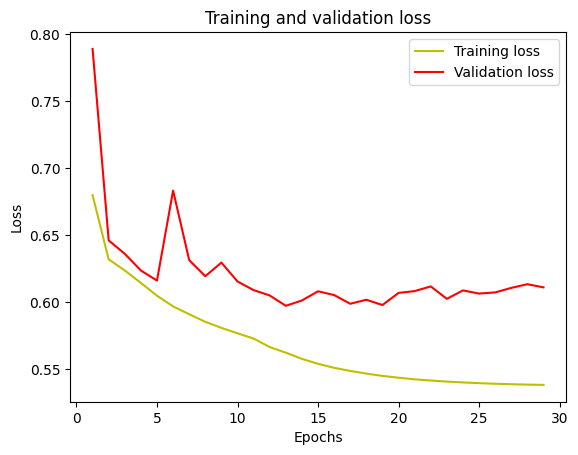

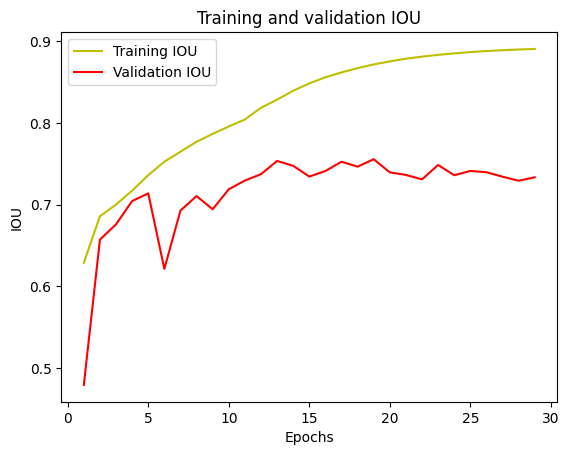

In [25]:
###
#plot the training and validation IoU and loss at each epoch
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, 'y', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

acc = history.history['iou_score']
val_acc = history.history['val_iou_score']

plt.plot(epochs, acc, 'y', label='Training IOU')
plt.plot(epochs, val_acc, 'r', label='Validation IOU')
plt.title('Training and validation IOU')
plt.xlabel('Epochs')
plt.ylabel('IOU')
plt.legend()
plt.show()

In [26]:
#Load the pretrained model for testing and predictions. 
from keras.models import load_model
# my_model = load_model('/content/drive/MyDrive/Colab Notebooks/data/sandstone_3d/3D_model_vgg16_100epochs.h5', compile=False)
#If you load a different model do not forget to preprocess accordingly. 

In [27]:
def preprocess_data(images, masks, n_classes=2):
    images = (images / 255).astype(np.uint8)
    masks = (masks / 255).astype(np.uint8)
    images = np.stack((images,) * 3, axis=-1)  # Empilhando os canais de imagem para RGB
    masks = np.expand_dims(masks, axis=-1)  # Expandindo dimensões das máscaras
    masks_cat = to_categorical(masks, num_classes=n_classes)
    return images, masks_cat

In [28]:
path_steel_stl= '../../steel/stl/'
folder = os.path.join(path_steel_stl, amostra)
file_combined = os.path.join(folder,'output_combined_matriz_fibras.tif')
file_fibras = os.path.join(folder,'output_fibras.tif')
input_shape = (64,64,64)
image = io.imread(file_combined)
img_patches = patchify(image, input_shape, step=64)
print(img_patches.shape)


path_test_folder = path_steel_stl + test_folder
# Dividindo os dados (test_folder para teste e o restante para treino)
test_images, test_masks = readImages(path_test_folder)
test_images, test_masks_cat = preprocess_data(test_images, test_masks, n_classes)

mask = io.imread(file_fibras)
mask_patches = patchify(mask, input_shape, step=64)

(4, 4, 4, 64, 64, 64)


In [29]:
pred = model.predict(test_images, batch_size=2)
pred.shape

2024-10-23 10:32:29.461427: E tensorflow/core/util/util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step


(64, 64, 64, 64, 2)

In [30]:
# Instanciando as métricas
iou_metric = sm.metrics.IOUScore(threshold=0.5)
fscore_metric = sm.metrics.FScore(threshold=0.5)

test_masks_cat = tf.cast(test_masks_cat, tf.float32)
pred = tf.cast(pred, tf.float32)

# Calculando as métricas
iou_value = iou_metric(test_masks_cat, pred).numpy()
fscore_value = fscore_metric(test_masks_cat, pred).numpy()

print("IOU Score:", iou_value)
print("Dice :", fscore_value)

IOU Score: 0.8065741
Dice : 0.8832997


In [31]:
tf.keras.backend.clear_session()
gc.collect()

0

In [32]:
pred_argmax = np.argmax(pred, axis=4)[:,:,:]

In [33]:
pred_argmax.shape

(64, 64, 64, 64)

In [34]:
pred_reshaped = np.reshape(pred_argmax, 
                                        (img_patches.shape[0], img_patches.shape[1], img_patches.shape[2],
                                         img_patches.shape[3], img_patches.shape[4], img_patches.shape[5]) )
print(pred_reshaped.shape)

(4, 4, 4, 64, 64, 64)


In [35]:
reconstructed_image = unpatchify(pred_reshaped, image.shape)
print(reconstructed_image.shape)

(256, 256, 256)


In [36]:
np.unique(reconstructed_image)

array([0, 1])

In [37]:
mask.shape

(256, 256, 256)

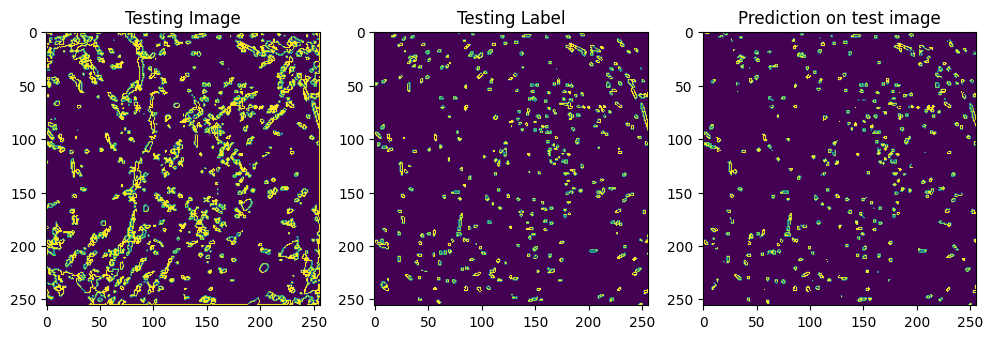

In [38]:
slice = 100
plt.figure(figsize=(12, 8))
plt.subplot(231)
plt.title('Testing Image')
plt.imshow(image[slice,:,:])
plt.subplot(232)
plt.title('Testing Label')
plt.imshow(mask[slice,:,:])
plt.subplot(233)
plt.title('Prediction on test image')
plt.imshow(reconstructed_image[slice,:,:])
plt.show()

In [39]:
from tifffile import imsave

def generate3D(name_model, amostra, reconstructed_image):
    
    name_file = '3D_result/'+ amostra + '_segmented.tif'
    imsave(name_file, reconstructed_image)

In [40]:
generate3D(name_model, amostra, reconstructed_image)

/tmp/ipykernel_77049/1701599428.py:6: DeprecationWarning: <tifffile.imsave> is deprecated. Use tifffile.imwrite
  imsave(name_file, reconstructed_image)
